In [1]:
import casadi as cas
import numpy as np
import json
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrow
from scipy.optimize import linear_sum_assignment

from typing import List, Dict

In [2]:
class Turtlebot:
    def __init__(self, x: float, y: float, w: float):
        self.x = x
        self.y = y
        self.w = w

    def move(self, v: float, w: float, dt: float):
        self.x = self.x + v * np.cos(w) * dt
        self.y = self.y + v * np.sin(w) * dt
        self.w = self.w + w * dt

    def set_goal(self, x, y, w):
        self.goal = [x, y, w]

    def plot(self, ax, color='blue', arrow_length=0.1, width=0.005, head_width=0.02):
        """
        dx = arrow_length * np.cos(self.w)
        dy = arrow_length * np.sin(self.w)

        arrow = FancyArrow(
            self.x,
            self.y,
            dx,
            dy,
            length_includes_head=True,
            width=width,
            head_width=head_width
        )
        ax.add_patch(arrow)
        """
        ax.scatter(self.x, self.y, color=color)

In [3]:
def dynamic_system(x, u, dt):
    # compute next position for current robot
    x_pos_next = x[0] + dt * u[0] * cas.cos(x[2])
    y_pos_next = x[1] + dt * u[0] * cas.sin(x[2])
    w_next = x[2] + dt * u[1]

    return cas.vertcat(x_pos_next, y_pos_next, w_next)

In [4]:
def compute_cost(x, u, x_ref, u_ref, Q, R):
    """
    Compute the cost function.

    Parameters:
        x: CasADi MX vector representing the current state
        u: CasADi MX vector representing the control input
        x_ref: CasADi MX vector representing the reference state
        u_ref: CasADi MX vector representing the reference control input
        Q: CasADi MX matrix representing the state cost matrix
        R: CasADi MX matrix representing the control cost matrix

    Returns:
        cost: CasADi expression representing the cost value
    """
    # Compute the state part of the cost
    state_cost = cas.dot(x - x_ref, cas.mtimes(Q, x - x_ref))

    # Compute the control part of the cost
    control_cost = cas.dot(u, cas.mtimes(R, u))

    # Total cost
    cost = state_cost + control_cost

    return cost

In [5]:
initial_pos = [1, 1, 0]
goal_pos = [0, 0, -np.pi/2]

# Turtlebot constraints
MAX_LINEAR_VELOCITY = 0.12   # m/s
MAX_ANGULAR_VELOCITY = 2.84   # rad/s
MAX_DELTA_VELOCITY = 1.5   # m/s
MAX_DELTA_OMEGA = np.pi/2.0   # rad/s

Iteration:  0  :  [1, 1, 0]
Iteration:  20  :  [1.011246387061616, 1.001537530371899, 0.6662882605902766]
Iteration:  40  :  [0.9960885846795863, 0.9848295572008609, 0.8338423068813016]
Iteration:  60  :  [0.9726380255313892, 0.980068313368293, 0.8739121511117836]
Iteration:  80  :  [0.9486841247725845, 0.9786402485291168, 0.8858215836864827]
Iteration:  100  :  [0.9246935142785466, 0.9779757116988508, 0.8913601427729899]
Iteration:  120  :  [0.9006984291885802, 0.9774904940635546, 0.8954039001880697]
Iteration:  140  :  [0.8767024294979847, 0.9770522692781709, 0.8990559762219499]
Iteration:  160  :  [0.8527061222524883, 0.9766311765827602, 0.9025652618406059]
Iteration:  180  :  [0.8287096295586318, 0.9762207825435745, 0.9059853786035253]


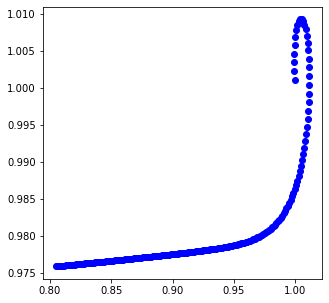

In [8]:
turtlebot = Turtlebot(initial_pos[0], initial_pos[1], initial_pos[2])

dt = 0.01
iterations = 200
T = 600

fig, ax = plt.subplots(figsize=(5,5))

for i in range(iterations):
    current_pos = [turtlebot.x, turtlebot.y, turtlebot.w]

    if i%20 == 0:
        print("Iteration: ", i, " : ", current_pos)

    opti = cas.Opti()
    
    # define variables
    x = opti.variable(3, T+1)
    u = opti.variable(2, T)
    
    # define parameters
    p = opti.parameter(3, 1)
    x_ref = opti.parameter(3, T+1)
    u_ref = opti.parameter(2, T)
    Q = opti.parameter(x.shape[0], x.shape[0])
    R = opti.parameter(u.shape[0], u.shape[0])
    
    # cost
    cost = compute_cost(x, u, x_ref, u_ref, Q, R)
    
    # tell casadi to minimize cost
    opti.minimize(cost)
    
    # define controll horizon
    for t in range(T):
        x_next = dynamic_system(x[:,t], u[:,t], dt)
        opti.subject_to(x[:, t+1] == x_next)
    
    # add constraints in change of velocity
    for t in range(T-1):
        dvel = u[:, t+1] - u[:, t]
    
        # limit maximum delta in velocity
        opti.subject_to(
            opti.bounded(-MAX_DELTA_VELOCITY, dvel[0], MAX_DELTA_VELOCITY)
        )
        # limit maximum delta in angular velocity
        opti.subject_to(
            opti.bounded(-MAX_DELTA_OMEGA, dvel[1], MAX_DELTA_OMEGA)
        )
    
    # add constraints for velocity
    opti.subject_to(
        opti.bounded(-MAX_LINEAR_VELOCITY, u[0], MAX_LINEAR_VELOCITY)
    )
    
    # add constraints for angular velocity
    opti.subject_to(
        opti.bounded(-MAX_ANGULAR_VELOCITY, u[0], MAX_ANGULAR_VELOCITY)
    )
    
    # maximum state values
    opti.subject_to(
        opti.bounded(-2.07, x[0], 2.07)
    )
    opti.subject_to(
        opti.bounded(-2.07, x[1], 2.07)
    )
    opti.subject_to(
        opti.bounded(-np.pi, x[2], np.pi)
    )
    
    # subject to initial position
    opti.subject_to(x[:,0] == p)
    
    # set paper values
    opti.set_value(Q, cas.diag(cas.vertcat([1.0, 5.0, 0.5])))
    opti.set_value(R, cas.diag(cas.vertcat([0.5, 0.25])))
    
    # set reference values
    #opti.set_value(x_ref, cas.DM.zeros(3, T+1))
    opti.set_value(x_ref, cas.repmat(goal_pos, 1, T+1))
    opti.set_value(u_ref, cas.DM.zeros(2, T))
    
    # initial values for u and i
    x_init = cas.repmat([0,0,0], 1, T+1)
    u_init = cas.repmat([0,0], 1, T)
    
    # set the initial guess
    opti.set_initial(x, x_init)
    opti.set_initial(u, u_init)
    
    # set initial state
    opti.set_value(p, current_pos)
    
    # solve
    solver_opts = {'ipopt.print_level': 0, 'print_time': 0}
    opti.solver('ipopt', solver_opts)
    solution = opti.solve()
    
    # warm start for next iteration
    #x_init = cas.repmat(x[:,0], 1, T+1)
    #u_init = cas.repmat(u[:,0], 1, T)

    # update turtlebot
    control_input = solution.value(u)[:,0]
    turtlebot.move(control_input[0], control_input[1], dt)
    turtlebot.plot(ax)

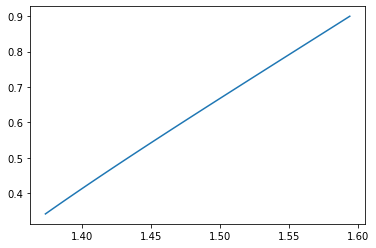

In [7]:
plt.plot(solution.value(x)[0,:], solution.value(x)[1,:])